# DareFX: EUR/USD Exploratory Data Analysis (2003 - 2026)

Phase 1 foundation analysis analyzing 23 years of institutional EUR/USD daily OHLCV bars:
- Historical macro regimes & structural shock events
- Logarithmic returns distribution vs. Gaussian ideal
- Multi-horizon rolling annualized volatility (21d, 63d, 252d)
- Return autocorrelation & volatility clustering (ARCH effect)

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

from darefx.data.storage import ParquetStorage

# Configure clean plot styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 120

storage = ParquetStorage(base_dir="../data/processed")
df = storage.load_daily_bars(symbol="EURUSD")
print(f"Loaded {len(df):,} daily bars from {df['timestamp'].min().date()} to {df['timestamp'].max().date()}")
df.tail()

Loaded 5,248 daily bars from 2003-12-01 to 2026-10-29


,timestamp,open,high,low,close,volume,tick_count
5243,2026-10-22 23:00:00+00:00,1.122158,1.122649,1.118706,1.122146,0.0,1000
5244,2026-10-26 00:00:00+00:00,1.121818,1.122712,1.117468,1.121755,0.0,1000
5245,2026-10-27 00:00:00+00:00,1.117531,1.117818,1.113611,1.117381,0.0,1000
5246,2026-10-28 00:00:00+00:00,1.113090,1.114082,1.111321,1.112966,0.0,1000
5247,2026-10-29 00:00:00+00:00,1.115822,1.116321,1.112966,1.115076,0.0,1000


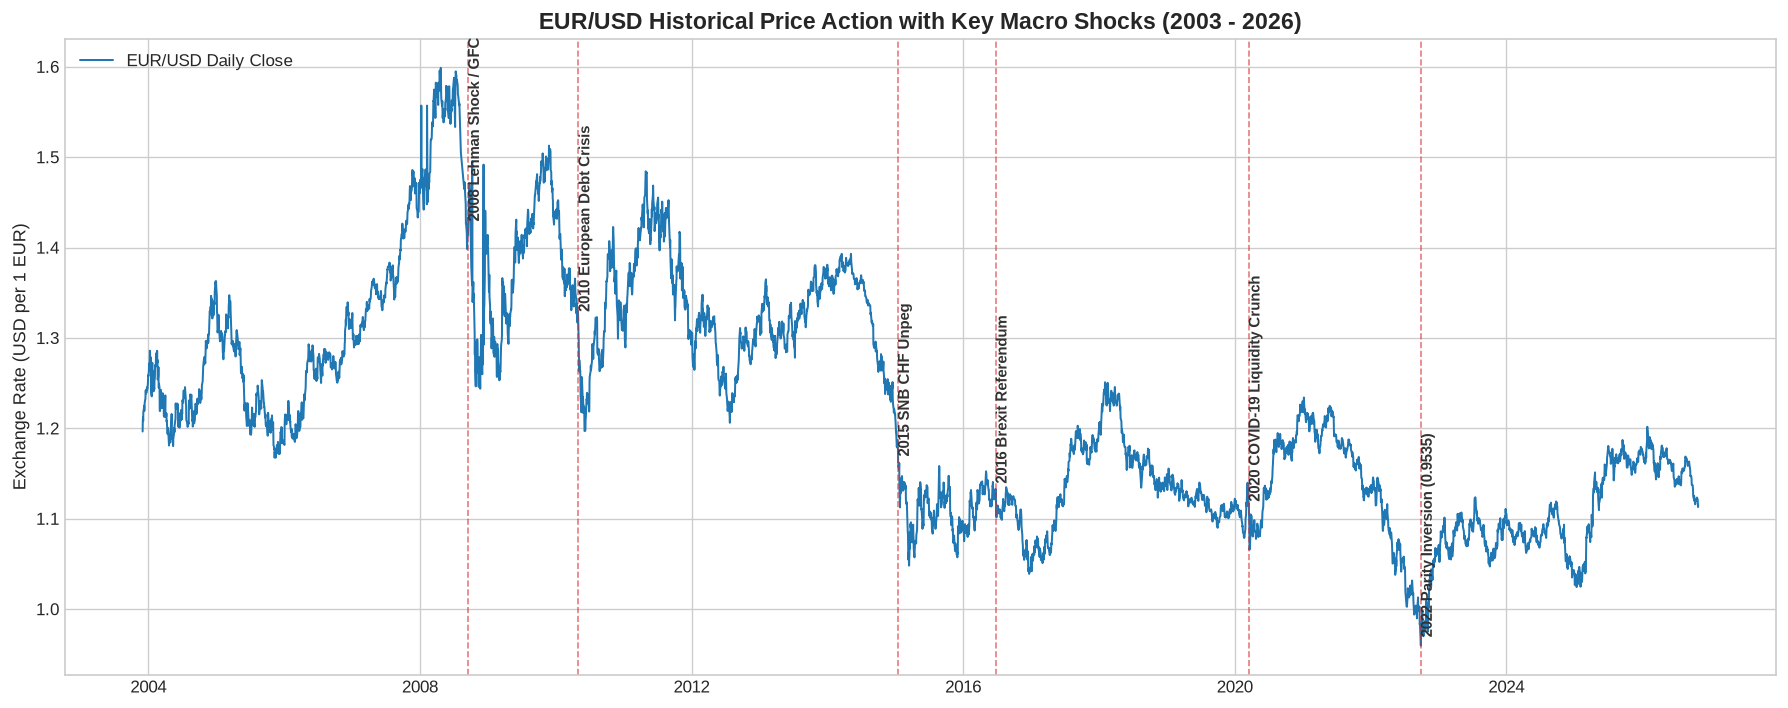

In [2]:
# 1. Plot 20-year price trajectory with historical macro events
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df["timestamp"], df["close"], label="EUR/USD Daily Close", color="#1f77b4", lw=1.2)

events = [
    ("2008-09-15", 1.42, "2008 Lehman Shock / GFC"),
    ("2010-05-02", 1.32, "2010 European Debt Crisis"),
    ("2015-01-15", 1.16, "2015 SNB CHF Unpeg"),
    ("2016-06-23", 1.13, "2016 Brexit Referendum"),
    ("2020-03-15", 1.11, "2020 COVID-19 Liquidity Crunch"),
    ("2022-09-28", 0.96, "2022 Parity Inversion (0.9535)")
]

for date_str, y_pos, label in events:
    dt = pd.to_datetime(date_str, utc=True)
    ax.axvline(dt, color="#d62728", ls="--", alpha=0.6, lw=1)
    ax.text(dt, y_pos, f"  {label}", rotation=90, verticalalignment="bottom", fontsize=9, color="#333", fontweight="bold")

ax.set_title("EUR/USD Historical Price Action with Key Macro Shocks (2003 - 2026)", fontsize=14, fontweight="bold")
ax.set_ylabel("Exchange Rate (USD per 1 EUR)", fontsize=11)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

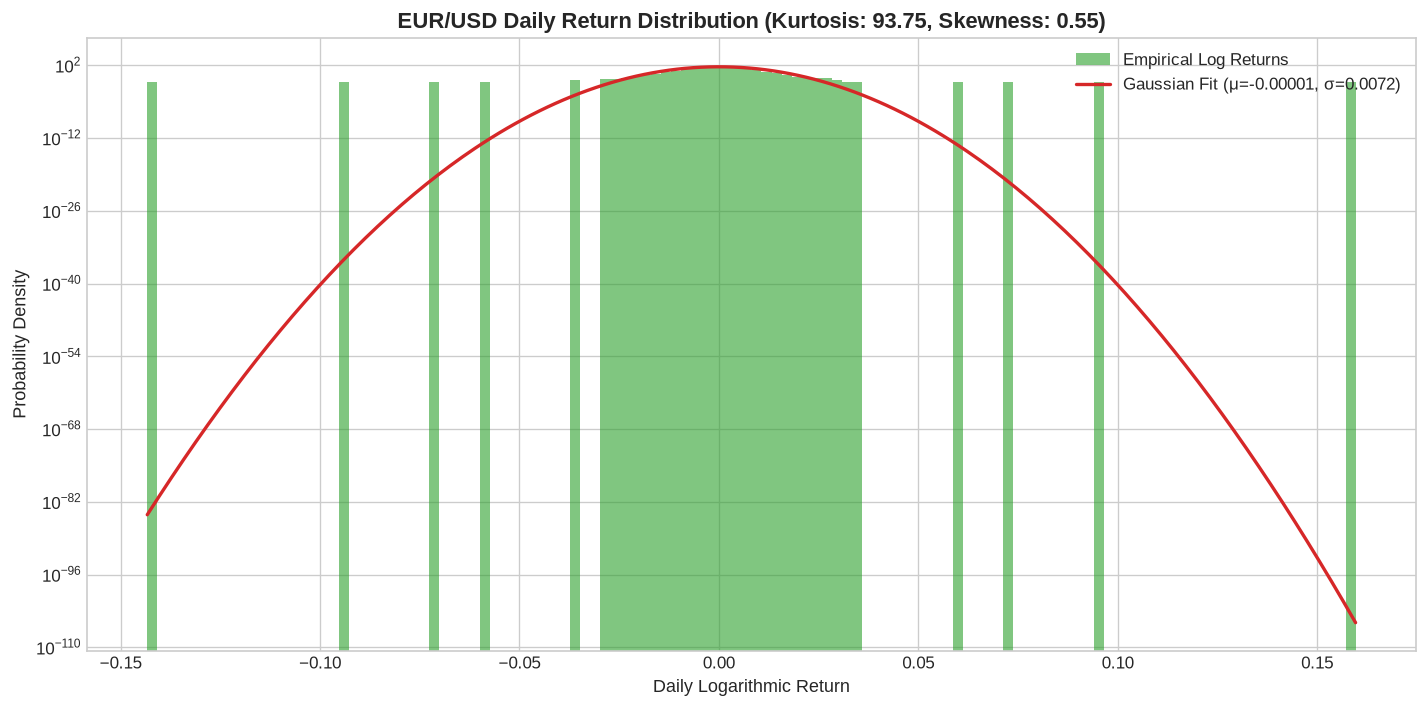

Kurtosis of 93.75 confirms heavy fat-tails (leptokurtic). Risk management must account for extreme moves.


In [3]:
# 2. Daily Log Return Distribution vs. Normal Distribution (Fat-Tail Analysis)
df["log_return"] = np.log(df["close"] / df["close"].shift(1))
returns = df["log_return"].dropna()

mu, sigma = returns.mean(), returns.std()
skewness = returns.skew()
kurtosis = returns.kurtosis()  # Excess kurtosis

fig, ax = plt.subplots(figsize=(12, 6))
count, bins, _ = ax.hist(returns, bins=120, density=True, alpha=0.6, color="#2ca02c", label="Empirical Log Returns")

# Overlay Gaussian bell curve
x = np.linspace(returns.min(), returns.max(), 300)
ax.plot(x, stats.norm.pdf(x, mu, sigma), color="#d62728", lw=2, label=f"Gaussian Fit (μ={mu:.5f}, σ={sigma:.4f})")

ax.set_title(f"EUR/USD Daily Return Distribution (Kurtosis: {kurtosis:.2f}, Skewness: {skewness:.2f})", fontsize=13, fontweight="bold")
ax.set_xlabel("Daily Logarithmic Return", fontsize=11)
ax.set_ylabel("Probability Density", fontsize=11)
ax.set_yscale("log")  # Log scale highlights fat tails
ax.legend()
plt.tight_layout()
plt.show()
print(f"Kurtosis of {kurtosis:.2f} confirms heavy fat-tails (leptokurtic). Risk management must account for extreme moves.")

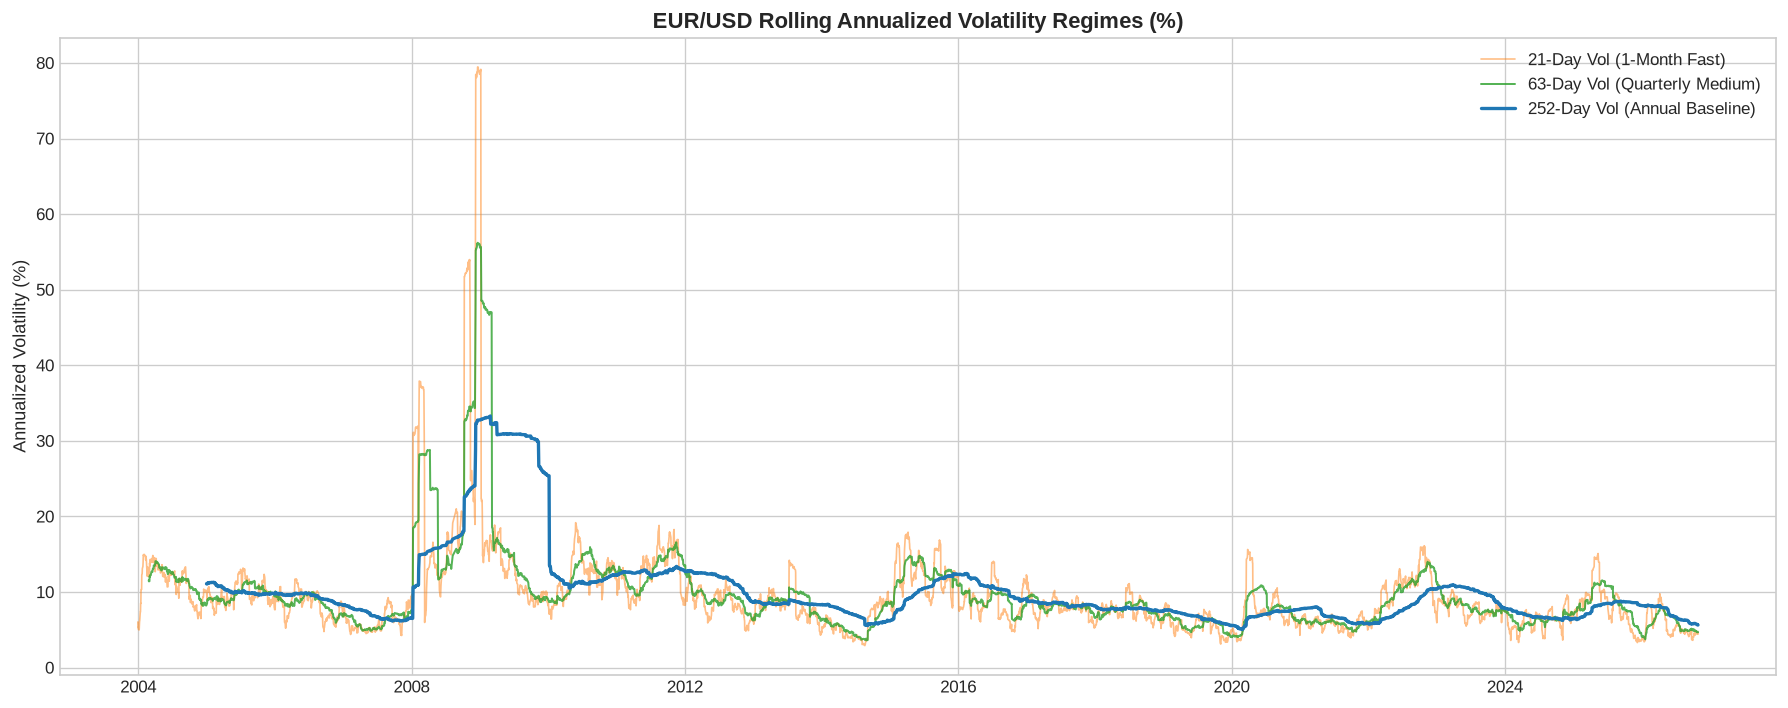

In [4]:
# 3. Multi-Horizon Rolling Annualized Volatility (252 trading days/year)
trading_days = 252
df["vol_21d"] = returns.rolling(21).std() * np.sqrt(trading_days) * 100
df["vol_63d"] = returns.rolling(63).std() * np.sqrt(trading_days) * 100
df["vol_252d"] = returns.rolling(252).std() * np.sqrt(trading_days) * 100

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df["timestamp"], df["vol_21d"], label="21-Day Vol (1-Month Fast)", alpha=0.5, color="#ff7f0e", lw=1)
ax.plot(df["timestamp"], df["vol_63d"], label="63-Day Vol (Quarterly Medium)", alpha=0.8, color="#2ca02c", lw=1.2)
ax.plot(df["timestamp"], df["vol_252d"], label="252-Day Vol (Annual Baseline)", color="#1f77b4", lw=2)

ax.set_title("EUR/USD Rolling Annualized Volatility Regimes (%)", fontsize=13, fontweight="bold")
ax.set_ylabel("Annualized Volatility (%)", fontsize=11)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

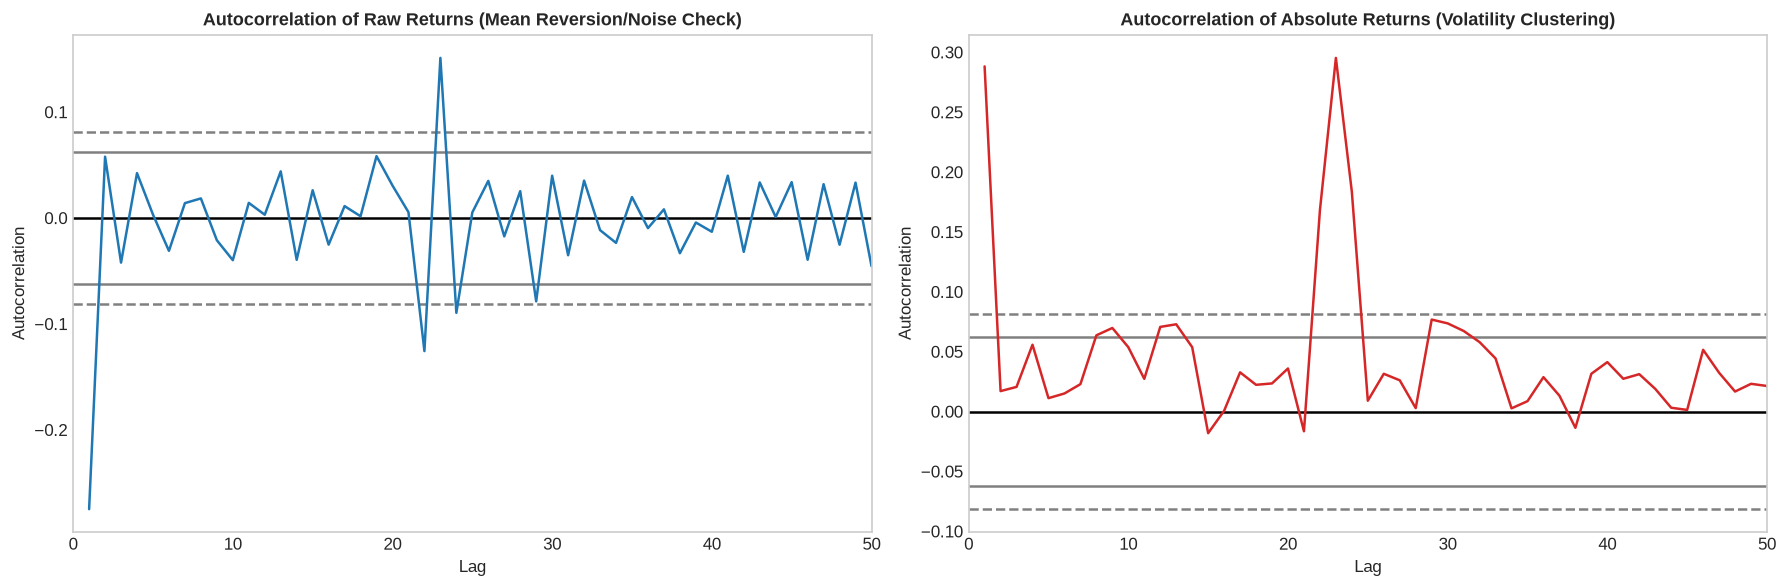

Takeaway: Raw daily returns show virtually zero linear autocorrelation (efficient market),
while absolute returns show strong, persistent memory -> volatility is predictable even if direction is noisy.


In [5]:
# 4. Return Autocorrelation & Volatility Clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

pd.plotting.autocorrelation_plot(returns.iloc[:1000], ax=ax1)
ax1.set_title("Autocorrelation of Raw Returns (Mean Reversion/Noise Check)", fontsize=11, fontweight="bold")
ax1.set_xlim(0, 50)

# Absolute returns display persistent volatility clustering (ARCH effect)
pd.plotting.autocorrelation_plot(returns.abs().iloc[:1000], ax=ax2, color="#d62728")
ax2.set_title("Autocorrelation of Absolute Returns (Volatility Clustering)", fontsize=11, fontweight="bold")
ax2.set_xlim(0, 50)

plt.tight_layout()
plt.show()
print("Takeaway: Raw daily returns show virtually zero linear autocorrelation (efficient market),")
print("while absolute returns show strong, persistent memory -> volatility is predictable even if direction is noisy.")